In [1]:
# Timer for notebook
import time
_start_time = time.perf_counter()

# Put imports here
import numpy as np
from scipy import stats, special, integrate, fft
import matplotlib.pyplot as plt
import mp3lib as ml

SEED = 690403480 # drawn 2026-11-23, do not change
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8, rng_A, rng_B = rng.spawn(10)

magnitude = 6
n = np.zeros(magnitude + 1, dtype=int)
for i in range(magnitude + 1):
    n[i] = 10 ** i

## Step 1

## Step 2

## Step 3

## Step 4

## Step 5

## Step 6

## Step 7

## Step 8

### Part 1: 
Each sensor reads $X_i = S + N_i$, and $S$ is independent of the noise. So

$$\Sigma_{xx} = \sigma_s^2\,\mathbf 1\mathbf 1^T + \Sigma_N =
\begin{bmatrix}5 & 4+c\\ 4+c & 6\end{bmatrix},
\qquad
\Sigma_{sx} = \begin{bmatrix}4\\4\end{bmatrix}.$$

$\Sigma_{sx}$ is $[4,4]^T$ because $\text{Cov}(S, X_i)=\text{Cov}(S,S)=4$, and the noise adds nothing.

### Part 2: 
For $\hat S = \mathbf w^T\mathbf X$, the mean squared error is
$$E[(S-\mathbf w^T\mathbf X)^2] = \sigma_s^2 - 2\mathbf w^T\Sigma_{sx} + \mathbf w^T\Sigma_{xx}\mathbf w.$$
Setting the gradient to zero gives $\Sigma_{xx}\mathbf w = \Sigma_{sx}$, so
$$\mathbf w = \Sigma_{xx}^{-1}\Sigma_{sx}, \qquad \text{MMSE} = \sigma_s^2 - \Sigma_{sx}^T\Sigma_{xx}^{-1}\Sigma_{sx}.$$

### Part 3: 
$\Sigma_N=\begin{bmatrix}1&c\\c&2\end{bmatrix}$ is positive definite when $1>0$ and $\det\Sigma_N = 2-c^2 > 0$.
So $|c| < \sqrt2 \approx 1.414$.

### Part 5: 

Multiplying $\Sigma_{xx}^{-1}$ by $\Sigma_{sx}=[4,4]^T$:
$$w_1=\frac{4(2-c)}{14-8c-c^2},\qquad w_2=\frac{4(1-c)}{14-8c-c^2}=\frac{4(1-c)}{30-(4+c)^2}.$$
The denominator is positive for all admissible $c$, so the sign of $w_2$ is the sign of $(1-c)$. It is zero exactly at $c=1$ and negative for $c>1$.

For the MMSE, $\Sigma_{sx}^T\mathbf w=4(w_1+w_2)=\dfrac{16(3-2c)}{14-8c-c^2}$, so
$$\text{MMSE}(c)=4-\frac{16(3-2c)}{14-8c-c^2}=\frac{4(14-8c-c^2)-16(3-2c)}{14-8c-c^2}=\frac{4(2-c^2)}{14-8c-c^2}.$$

Differentiate with the quotient rule, with $N=8-4c^2$ and $D=14-8c-c^2$:
$$N'D-ND'=-8c(14-8c-c^2)-(8-4c^2)(-8-2c)=32c^2-96c+64=32(c-1)(c-2).$$
$$\frac{d\,\text{MMSE}}{dc}=\frac{32(c-1)(c-2)}{(14-8c-c^2)^2}.$$
This is zero at $c=1$ (the root $c=2$ is outside the admissible range). For $c<1$ both factors are negative, so the derivative is positive. For $1<c<\sqrt2$ it is negative. The derivative changes from $+$ to $-$, so $c=1$ is a **maximum**, not a minimum. At $c=1$ the MMSE is $4/5=0.8$, which equals the best single sensor.

    c         w1         w2       MMSE  best 1 sensor  equal (avg)
 -1.4   0.585198   0.413081   0.006885       0.800000     0.050000
 -1.0   0.571429   0.380952   0.190476       0.800000     0.250000
 -0.5   0.563380   0.338028   0.394366       0.800000     0.500000
  0.0   0.571429   0.285714   0.571429       0.800000     0.750000
  0.5   0.615385   0.205128   0.717949       0.800000     1.000000
  1.0   0.800000   0.000000   0.800000       0.800000     1.250000
  1.2   1.081081  -0.270270   0.756757       0.800000     1.350000
  1.4   2.857143  -1.904762   0.190476       0.800000     1.450000

Max |w2 numeric - closed form| = 1.44e-14
Max |MMSE numeric - closed form| = 5.77e-15
MMSE(0.99) = 0.799937, MMSE(1) = 0.800000, MMSE(1.01) = 0.799935
Largest MMSE on the grid = 0.799996 at c = 1.002
MMSE(-1) = 0.190476, MMSE(1.4) = 0.190476


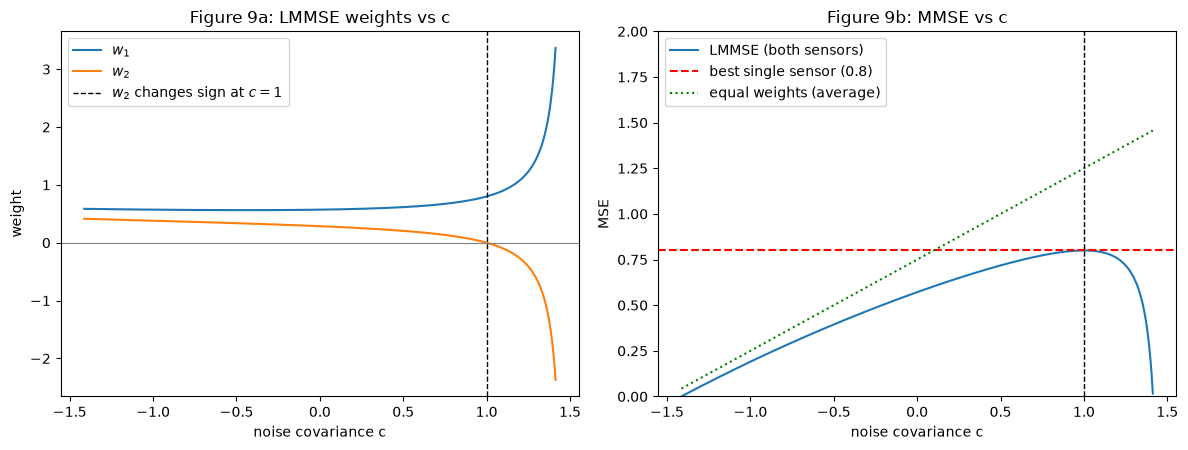

c = 0.8: simulated MSE = 0.78036 +/- 0.00110, analytic = 0.78161, difference = -0.00125 (1.13 SE)
c = 1.4: simulated MSE = 0.19080 +/- 0.00027, analytic = 0.19048, difference = +0.00032 (1.20 SE)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sig2 = 4.0
ones = np.ones(2)
Sigma_sx = sig2 * ones                       # [4, 4]

def sigma_N(c):
    return np.array([[1.0, c], [c, 2.0]])

def sigma_xx(c):
    return sig2 * np.outer(ones, ones) + sigma_N(c)

def lmmse(c):
    w = ml.lmmse_weights(sigma_xx(c), Sigma_sx)
    return w, sig2 - Sigma_sx @ w            # weights, MMSE

def mse_of(w, c):
    # S - w^T X = S(1 - sum w) - w^T N, so the error variance is:
    return sig2 * (1 - w.sum())**2 + w @ sigma_N(c) @ w

best_single = min(sig2 * 1 / (sig2 + 1), sig2 * 2 / (sig2 + 2))   # sensor 1 alone = 0.8

# Part 4: table
c_list = [-1.4, -1.0, -0.5, 0.0, 0.5, 1.0, 1.2, 1.4]
print(f"{'c':>5} {'w1':>10} {'w2':>10} {'MMSE':>10} {'best 1 sensor':>14} {'equal (avg)':>12}")
for c in c_list:
    w, m = lmmse(c)
    eq = mse_of(np.array([0.5, 0.5]), c)
    print(f"{c:5.1f} {w[0]:10.6f} {w[1]:10.6f} {m:10.6f} {best_single:14.6f} {eq:12.6f}")

# Part 5: check closed forms against the numerical solve over the whole range
cs = np.linspace(-np.sqrt(2) + 1e-3, np.sqrt(2) - 1e-3, 400)
W = np.array([lmmse(c)[0] for c in cs])
M = np.array([lmmse(c)[1] for c in cs])
den = 14 - 8 * cs - cs**2
err_w2 = np.max(np.abs(W[:, 1] - 4 * (1 - cs) / den))
err_m = np.max(np.abs(M - 4 * (2 - cs**2) / den))
print(f"\nMax |w2 numeric - closed form| = {err_w2:.2e}")
print(f"Max |MMSE numeric - closed form| = {err_m:.2e}")
print(f"MMSE(0.99) = {lmmse(0.99)[1]:.6f}, MMSE(1) = {lmmse(1.0)[1]:.6f}, MMSE(1.01) = {lmmse(1.01)[1]:.6f}")
print(f"Largest MMSE on the grid = {M.max():.6f} at c = {cs[M.argmax()]:.3f}")
print(f"MMSE(-1) = {lmmse(-1.0)[1]:.6f}, MMSE(1.4) = {lmmse(1.4)[1]:.6f}")

# Figure 9
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

ax[0].plot(cs, W[:, 0], label="$w_1$")
ax[0].plot(cs, W[:, 1], label="$w_2$")
ax[0].axhline(0, color="gray", lw=0.8)
ax[0].axvline(1, color="k", ls="--", lw=1, label="$w_2$ changes sign at $c=1$")
ax[0].set_xlabel("noise covariance c"); ax[0].set_ylabel("weight")
ax[0].set_title("Figure 9a: LMMSE weights vs c"); ax[0].legend()

ax[1].plot(cs, M, label="LMMSE (both sensors)")
ax[1].axhline(best_single, color="r", ls="--", label="best single sensor (0.8)")
ax[1].plot(cs, [mse_of(np.array([0.5, 0.5]), c) for c in cs], color="g", ls=":", label="equal weights (average)")
ax[1].axvline(1, color="k", ls="--", lw=1)
ax[1].set_ylim(0, 2)
ax[1].set_xlabel("noise covariance c"); ax[1].set_ylabel("MSE")
ax[1].set_title("Figure 9b: MMSE vs c"); ax[1].legend()
plt.tight_layout(); plt.show()

# Part 9: Monte Carlo at c = 0.8 and c = 1.4
N8 = 10**6
mc = {}
for c in [0.8, 1.4]:
    w, m = lmmse(c)
    S = np.sqrt(sig2) * rng_8.standard_normal(N8)
    noise = rng_8.multivariate_normal([0, 0], sigma_N(c), size=N8)
    X = S[:, None] + noise
    e2 = (S - X @ w)**2
    mc[c] = (e2.mean(), e2.std(ddof=1) / np.sqrt(N8), m)
    print(f"c = {c}: simulated MSE = {mc[c][0]:.5f} +/- {mc[c][1]:.5f}, analytic = {m:.5f}, "
          f"difference = {mc[c][0] - m:+.5f} ({abs(mc[c][0] - m) / mc[c][1]:.2f} SE)")

In [3]:
m0 = lmmse(0.0)[1]
m14 = lmmse(1.4)[1]
w14 = lmmse(1.4)[0]
var_diff = 1 + 2 - 2 * 1.4          # Var(X1 - X2) = Var(N1 - N2) = 1 + 2 - 2c

display(Markdown(f"""
**Part 4 (table).** Both-sensor LMMSE is never worse than the best single sensor ({best_single:.3f}) or the
plain average. At c = 0 the MMSE is {m0:.4f}. The two baselines only match the optimum at c = 1.

**Part 5 (c = 1).** The numerical weights match the closed forms (max difference {err_w2:.1e} for w2 and
{err_m:.1e} for the MMSE). At c = 1, w2 = 0 and the MMSE is {lmmse(1.0)[1]:.4f}, the same as sensor 1
alone. The MMSE just below and just above c = 1 is {lmmse(0.99)[1]:.5f} and {lmmse(1.01)[1]:.5f}, both
below {lmmse(1.0)[1]:.5f}, so c = 1 is a **maximum** of the MMSE, not a minimum. This is because
Cov(N1, N2 - N1) = c - 1 = 0 at c = 1. The difference X2 - X1 = N2 - N1 then has nothing to do with N1, and
it contains no S, so sensor 2 adds no usable information.

**Part 6 (negative weight).** For c > 1 the estimator uses X1 - X2 = N1 - N2, which contains no S at all, only
noise. Its variance is 3 - 2c, which is {var_diff:.2f} at c = 1.4, so it is a very precise reading of
N1 - N2. Since Cov(N1, N1 - N2) = 1 - c is negative, learning N1 - N2 tells us the noise in sensor 1,
and we subtract that noise off. The weights at c = 1.4 are w = [{w14[0]:.4f}, {w14[1]:.4f}]. The estimator
is not subtracting a measurement of S, it is subtracting a measurement of the noise.

**Part 7.** The MMSE is {m0:.4f} at c = 0 and {m14:.4f} at c = 1.4, a drop of
{(1 - m14 / m0) * 100:.0f} percent. Correlated noise helps because the noise is shared. When the two noises
move together, the difference of the readings cancels S and isolates the noise, which gives us a way to remove it.
Independent noise gives us no such handle.

**Part 8 (shape of the curve).** The MMSE rises from near 0 at c = -sqrt(2) up to its largest value, {M.max():.4f},
at c = 1, then falls back toward 0 as c goes to +sqrt(2). So c = 1 is the worst admissible c, the one
point where the second sensor is useless. At both ends of the range the noises are perfectly correlated
(N2 = plus or minus sqrt(2) N1), so the noise can be cancelled exactly and the MMSE goes to 0.
The values are also not symmetric: MMSE(-1) and MMSE(1.4) are both {lmmse(1.4)[1]:.4f}.

**Part 9 (Monte Carlo).** At c = 0.8 the simulated MSE is {mc[0.8][0]:.4f} ± {mc[0.8][1]:.4f} against an
analytic {mc[0.8][2]:.4f}. At c = 1.4 it is {mc[1.4][0]:.4f} ± {mc[1.4][1]:.4f} against {mc[1.4][2]:.4f}.
Both agree within about {max(abs(mc[0.8][0]-mc[0.8][2])/mc[0.8][1], abs(mc[1.4][0]-mc[1.4][2])/mc[1.4][1]):.1f} standard errors.
"""))


**Part 4 (table).** Both-sensor LMMSE is never worse than the best single sensor (0.800) or the
plain average. At c = 0 the MMSE is 0.5714. The two baselines only match the optimum at c = 1.

**Part 5 (c = 1).** The numerical weights match the closed forms (max difference 1.4e-14 for w2 and
5.8e-15 for the MMSE). At c = 1, w2 = 0 and the MMSE is 0.8000, the same as sensor 1
alone. The MMSE just below and just above c = 1 is 0.79994 and 0.79993, both
below 0.80000, so c = 1 is a **maximum** of the MMSE, not a minimum. This is because
Cov(N1, N2 - N1) = c - 1 = 0 at c = 1. The difference X2 - X1 = N2 - N1 then has nothing to do with N1, and
it contains no S, so sensor 2 adds no usable information.

**Part 6 (negative weight).** For c > 1 the estimator uses X1 - X2 = N1 - N2, which contains no S at all, only
noise. Its variance is 3 - 2c, which is 0.20 at c = 1.4, so it is a very precise reading of
N1 - N2. Since Cov(N1, N1 - N2) = 1 - c is negative, learning N1 - N2 tells us the noise in sensor 1,
and we subtract that noise off. The weights at c = 1.4 are w = [2.8571, -1.9048]. The estimator
is not subtracting a measurement of S, it is subtracting a measurement of the noise.

**Part 7.** The MMSE is 0.5714 at c = 0 and 0.1905 at c = 1.4, a drop of
67 percent. Correlated noise helps because the noise is shared. When the two noises
move together, the difference of the readings cancels S and isolates the noise, which gives us a way to remove it.
Independent noise gives us no such handle.

**Part 8 (shape of the curve).** The MMSE rises from near 0 at c = -sqrt(2) up to its largest value, 0.8000,
at c = 1, then falls back toward 0 as c goes to +sqrt(2). So c = 1 is the worst admissible c, the one
point where the second sensor is useless. At both ends of the range the noises are perfectly correlated
(N2 = plus or minus sqrt(2) N1), so the noise can be cancelled exactly and the MMSE goes to 0.
The values are also not symmetric: MMSE(-1) and MMSE(1.4) are both 0.1905.

**Part 9 (Monte Carlo).** At c = 0.8 the simulated MSE is 0.7804 ± 0.0011 against an
analytic 0.7816. At c = 1.4 it is 0.1908 ± 0.0003 against 0.1905.
Both agree within about 1.2 standard errors.


### Part 10: 

I would pick the correlated-noise pair, as long as c is not close to 1. Shared interference can be cancelled
by comparing the two sensors, and the benefit grows as the correlation gets stronger. The catch is that the
weights depend on knowing the noise covariance accurately. Near the ends of the range the weight on sensor 2
is large (w2 = -1.9 at c = 1.4), so a small error in c causes a large error in the estimate. I would measure
the noise covariance with no signal present and re-measure it if temperature or power conditions change.

## Bonus A

## Bonus B

In [4]:
_end_time = time.perf_counter()
print(f"Total Notebook Runtime: {_end_time - _start_time:.3f} seconds")

Total Notebook Runtime: 9.789 seconds
